# 📈 03. Hidden Markov Model (HMM) - IPO Market Mood / Regime Detection

**Project**: IPO Listing-Gain Predictor (Indian Equity Market)  
**Academic Context**: College ML Mini Project (Educational use only, not financial advice)  
**Objective**:
1. Implement a **Discrete Hidden Markov Model (HMM)** from scratch in NumPy with **Forward** (scaled), **Backward**, **Baum-Welch (EM)**, and **Viterbi** algorithms.
2. Aggregate monthly IPO debut gains and discretize into 3 observation symbols: `Low`, `Medium`, `High` using quantile thresholds derived **strictly on training months**.
3. Train a 3-state HMM representing market regimes: **Cold**, **Warm**, and **Hot**.
4. Use **Viterbi** to decode the most probable sequence of market moods and **Forward** to calculate sequence log-likelihood.
5. Create a causal, **leakage-free `market_mood` feature** for every IPO using only the decoded state of months strictly prior to listing.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import joblib

# Add project root to sys.path
sys.path.insert(0, os.path.abspath(".."))
from src.hmm import DiscreteHMM

# Aesthetic styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

FIG_DIR = os.path.join("..", "reports", "figures")
os.makedirs(FIG_DIR, exist_ok=True)
print("Modules imported and environment configured.")

Modules imported and environment configured.


## 1. Monthly IPO Gain Aggregation & Discretization

We aggregate individual IPO listing returns by month ($t$) to capture overarching sentiment cycles.
To avoid data leakage, quantile thresholds for discretizing returns into `Low`, `Medium`, and `High` are **computed strictly on the training months**.

In [2]:
DATA_DIR = os.path.join("..", "data", "processed")
if not os.path.exists(DATA_DIR):
    DATA_DIR = os.path.join("data", "processed")

# Load full cleaned dataset
df_clean = pd.read_csv(os.path.join(DATA_DIR, "ipo_clean.csv"))
df_clean['listing_date'] = pd.to_datetime(df_clean['listing_date'])
df_clean['month'] = df_clean['listing_date'].dt.to_period('M')

# Identify training cutoff date from train.csv
train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
train_df['listing_date'] = pd.to_datetime(train_df['listing_date'])
train_df['month'] = train_df['listing_date'].dt.to_period('M')

train_last_month = train_df['month'].max()
print(f"Training spans up to: {train_last_month}")

# Monthly average listing gain
monthly_df = df_clean.groupby('month').agg(
    avg_listing_gain_pct=('listing_gain_pct', 'mean'),
    ipo_count=('ipo_name', 'count')
).reset_index()

monthly_df['is_train'] = monthly_df['month'] <= train_last_month
monthly_train = monthly_df[monthly_df['is_train']]

print(f"Total months: {len(monthly_df)} (Train: {len(monthly_train)}, Test: {len(monthly_df) - len(monthly_train)})")

# Compute tertile thresholds (33.3% and 66.7%) on training months only
q_low = float(np.quantile(monthly_train['avg_listing_gain_pct'], 1/3))
q_high = float(np.quantile(monthly_train['avg_listing_gain_pct'], 2/3))

print(f"Training Discretization Thresholds:")
print(f"  - Low Gain    : < {q_low:.2f}%")
print(f"  - Medium Gain : [{q_low:.2f}%, {q_high:.2f}%)")
print(f"  - High Gain   : >= {q_high:.2f}%")

def discretize_gain(val):
    if val < q_low:
        return 0  # Low
    elif val < q_high:
        return 1  # Medium
    else:
        return 2  # High

monthly_df['obs_symbol'] = monthly_df['avg_listing_gain_pct'].apply(discretize_gain)
symbol_labels = {0: 'Low', 1: 'Medium', 2: 'High'}
monthly_df['obs_label'] = monthly_df['obs_symbol'].map(symbol_labels)

monthly_df.head(6)

Training spans up to: 2024-01
Total months: 48 (Train: 37, Test: 11)
Training Discretization Thresholds:
  - Low Gain    : < 13.95%
  - Medium Gain : [13.95%, 17.36%)
  - High Gain   : >= 17.36%


,month,avg_listing_gain_pct,ipo_count,is_train,obs_symbol,obs_label
0,2021-01,18.285000,4,True,2,High
1,2021-02,16.117500,4,True,1,Medium
2,2021-03,14.650000,6,True,1,Medium
3,2021-04,12.681429,7,True,0,Low
4,2021-05,17.364286,7,True,2,High
5,2021-06,6.850000,5,True,0,Low


## 2. Train 3-State HMM via Baum-Welch (EM)

We instantiate our custom NumPy `DiscreteHMM`:
- **Hidden States** ($N=3$): `Cold`, `Warm`, `Hot`
- **Emission Symbols** ($M=3$): `Low` (0), `Medium` (1), `High` (2)
- Training sequence: observation symbols from the **training months only**.

In [3]:
# Extract training observation sequence
train_obs = monthly_df[monthly_df['is_train']]['obs_symbol'].to_numpy()

# Initialize and fit Discrete HMM
hmm = DiscreteHMM(
    n_states=3,
    n_emissions=3,
    max_iter=100,
    tol=1e-4,
    random_state=42,
    state_names=['Cold', 'Warm', 'Hot']
)

hmm.fit(train_obs)

print("=" * 60)
print("BAUM-WELCH PARAMETER ESTIMATION RESULTS")
print("=" * 60)
print(f"Convergence achieved in: {len(hmm.log_likelihood_history_)} iterations")
print(f"Initial State Probabilities (pi):\n{np.round(hmm.pi_, 4)}")

state_names = hmm.state_names
df_A = pd.DataFrame(np.round(hmm.A_, 3), index=state_names, columns=state_names)
print(f"\nTransition Matrix (A) [P(State_t+1 | State_t)]:\n{df_A}")

df_B = pd.DataFrame(np.round(hmm.B_, 3), index=state_names, columns=['Low', 'Medium', 'High'])
print(f"\nEmission Matrix (B) [P(Observation | State)]:\n{df_B}")
print("=" * 60)

BAUM-WELCH PARAMETER ESTIMATION RESULTS
Convergence achieved in: 56 iterations
Initial State Probabilities (pi):
[0. 0. 1.]

Transition Matrix (A) [P(State_t+1 | State_t)]:
       Cold   Warm    Hot
Cold  0.000  0.580  0.420
Warm  0.707  0.161  0.132
Hot   0.615  0.000  0.385

Emission Matrix (B) [P(Observation | State)]:
        Low  Medium  High
Cold  0.732   0.268   0.0
Warm  0.143   0.857   0.0
Hot   0.000   0.000   1.0


## 3. Viterbi Decoding & Forward Likelihood Evaluation

1. **Viterbi Decoding**: Finds the global maximum a posteriori (MAP) state sequence across the entire timeline:
   $$\hat{Q} = \arg\max_{Q} P(Q, O \mid \lambda)$$
2. **Forward Evaluation**: Computes the exact scaled log-likelihood $\log P(O_{6m} \mid \lambda)$ for the most recent 6-month sequence.

In [4]:
# 1. Decode full observation sequence using Viterbi
all_obs = monthly_df['obs_symbol'].to_numpy()
viterbi_states, viterbi_names = hmm.decode(all_obs)

monthly_df['decoded_state_idx'] = viterbi_states
monthly_df['market_mood'] = viterbi_names

# 2. Evaluate likelihood of the most recent 6 months using Forward algorithm
recent_6m_obs = all_obs[-6:]
log_ll_6m, alpha_scaled, _ = hmm.forward(recent_6m_obs)
prob_6m = np.exp(log_ll_6m)

recent_months = monthly_df['month'].iloc[-6:].astype(str).tolist()
recent_moods = monthly_df['market_mood'].iloc[-6:].tolist()

print("=" * 60)
print("FORWARD ALGORITHM EVALUATION (Most Recent 6 Months)")
print("=" * 60)
print(f"Recent Months Sequence : {recent_months}")
print(f"Observation Symbols    : {recent_6m_obs.tolist()} ({[symbol_labels[s] for s in recent_6m_obs]})")
print(f"Decoded Market Moods   : {recent_moods}")
print(f"Forward Log-Likelihood : {log_ll_6m:.4f}")
print(f"Sequence Likelihood    : {prob_6m:.6e}")
print("=" * 60)

FORWARD ALGORITHM EVALUATION (Most Recent 6 Months)
Recent Months Sequence : ['2024-07', '2024-08', '2024-09', '2024-10', '2024-11', '2024-12']
Observation Symbols    : [1, 1, 1, 1, 0, 2] (['Medium', 'Medium', 'Medium', 'Medium', 'Low', 'High'])
Decoded Market Moods   : ['Warm', 'Warm', 'Cold', 'Warm', 'Cold', 'Hot']
Forward Log-Likelihood : -17.8361
Sequence Likelihood    : 1.794314e-08


## 4. Visualizing Monthly Gain with Decoded Market Mood

We plot the monthly average listing gains overlaid with colored background regions representing the HMM-decoded market regime:
- 🔵 **Cold** (Soft Blue): Conservative market, low subscription and muted listing gains.
- 🟡 **Warm** (Soft Yellow): Balanced market sentiment.
- 🔴 **Hot** (Soft Red): Euphoric market, high momentum and large listing pops.

Saved figure -> ..\reports\figures\08_hmm_market_mood.png


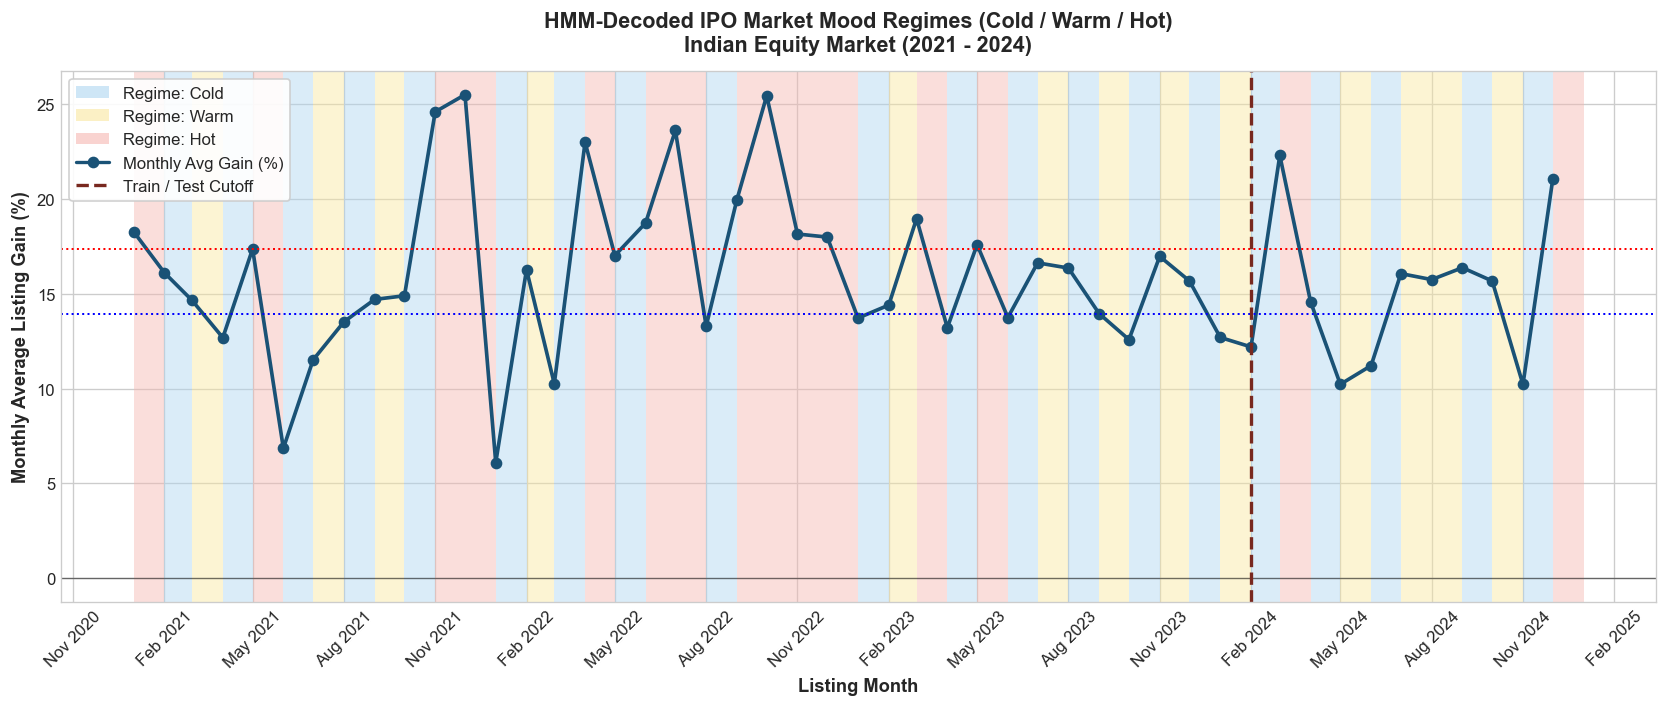

In [5]:
# Convert Period to timestamp for plotting
monthly_df['timestamp'] = monthly_df['month'].dt.to_timestamp()

fig, ax = plt.subplots(figsize=(14, 6))

mood_colors = {
    'Cold': '#aed6f1',  # Light Blue
    'Warm': '#f9e79f',  # Light Yellow / Amber
    'Hot':  '#f5b7b1',  # Light Red / Coral
}

# Color background spans per month
for idx, row in monthly_df.iterrows():
    t_start = row['timestamp']
    t_end = t_start + pd.DateOffset(months=1)
    color = mood_colors[row['market_mood']]
    ax.axvspan(t_start, t_end, color=color, alpha=0.45, lw=0)

# Plot monthly average gain line
ax.plot(
    monthly_df['timestamp'],
    monthly_df['avg_listing_gain_pct'],
    color='#1a5276',
    marker='o',
    markersize=6,
    linewidth=2.2,
    label='Monthly Avg Listing Gain (%)'
)

# Benchmark thresholds
ax.axhline(q_low, color='blue', linestyle=':', linewidth=1.2, label=f'Low Threshold ({q_low:.1f}%)')
ax.axhline(q_high, color='red', linestyle=':', linewidth=1.2, label=f'High Threshold ({q_high:.1f}%)')
ax.axhline(0, color='black', linestyle='-', linewidth=0.8, alpha=0.5)

# Train/Test boundary line
cutoff_timestamp = monthly_train['month'].max().to_timestamp() + pd.DateOffset(months=1)
ax.axvline(cutoff_timestamp, color='#78281f', linestyle='--', linewidth=2.0, label='Train/Test Temporal Split Boundary')

ax.set_title("HMM-Decoded IPO Market Mood Regimes (Cold / Warm / Hot)\nIndian Equity Market (2021 - 2024)", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Listing Month", fontsize=11, fontweight='semibold')
ax.set_ylabel("Monthly Average Listing Gain (%)", fontsize=11, fontweight='semibold')

# Format x-axis dates
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45)

# Custom legend with patches for moods
from matplotlib.patches import Patch
custom_legend = [
    Patch(facecolor=mood_colors['Cold'], edgecolor='none', alpha=0.6, label='Regime: Cold'),
    Patch(facecolor=mood_colors['Warm'], edgecolor='none', alpha=0.6, label='Regime: Warm'),
    Patch(facecolor=mood_colors['Hot'], edgecolor='none', alpha=0.6, label='Regime: Hot'),
    plt.Line2D([0], [0], color='#1a5276', marker='o', lw=2, label='Monthly Avg Gain (%)'),
    plt.Line2D([0], [0], color='#78281f', linestyle='--', lw=2, label='Train / Test Cutoff')
]
ax.legend(handles=custom_legend, loc='upper left', frameon=True, framealpha=0.9)

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "08_hmm_market_mood.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure -> {fig_path}")
plt.show()

## 5. Strict Zero-Leakage Feature Engineering

### The Golden Rule of Causal Feature Generation:
When an IPO lists in month $M$, investors only know the market mood from **strictly completed prior months** ($M-1$ or earlier).
- If IPO lists in `2024-05`, its `market_mood` feature is assigned the decoded state of `2024-04`.
- For IPOs in the very first recorded month (`2021-01`), it defaults to the HMM initial state (`Cold`).
This guarantees **ZERO look-ahead bias** and strictly prevents future listing outcome data from contaminating feature inputs.

In [6]:
# Create lookup map of month -> previous month's decoded mood
monthly_df_sorted = monthly_df.sort_values(by='month').reset_index(drop=True)

mood_map = {}
default_prior_mood = 'Cold'  # Initial prior state for the earliest month

for i in range(len(monthly_df_sorted)):
    curr_month = monthly_df_sorted.loc[i, 'month']
    if i == 0:
        mood_map[curr_month] = default_prior_mood
    else:
        # Strictly look at the previous month's decoded mood
        prior_mood = monthly_df_sorted.loc[i - 1, 'market_mood']
        mood_map[curr_month] = prior_mood

# Apply causal mapping to datasets
train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

train_df['listing_date'] = pd.to_datetime(train_df['listing_date'])
test_df['listing_date'] = pd.to_datetime(test_df['listing_date'])

train_df['month'] = train_df['listing_date'].dt.to_period('M')
test_df['month'] = test_df['listing_date'].dt.to_period('M')

train_df['market_mood'] = train_df['month'].map(mood_map).fillna('Cold')
test_df['market_mood'] = test_df['month'].map(mood_map).fillna('Cold')

print("Distribution of causal market_mood in Train set:")
print(train_df['market_mood'].value_counts())
print("\nDistribution of causal market_mood in Test set:")
print(test_df['market_mood'].value_counts())

Distribution of causal market_mood in Train set:
market_mood
Cold    91
Hot     81
Warm    53
Name: count, dtype: int64

Distribution of causal market_mood in Test set:
market_mood
Cold    38
Warm    29
Hot      8
Name: count, dtype: int64


In [7]:
# Save monthly summary with decoded mood
monthly_save_path = os.path.join(DATA_DIR, "monthly_market_mood.csv")
monthly_df[['month', 'avg_listing_gain_pct', 'ipo_count', 'obs_symbol', 'obs_label', 'market_mood', 'is_train']].to_csv(monthly_save_path, index=False)
print(f"[SAVE] Exported monthly mood table -> {monthly_save_path}")

# Save train and test with market_mood
train_with_mood_path = os.path.join(DATA_DIR, "train_with_mood.csv")
test_with_mood_path = os.path.join(DATA_DIR, "test_with_mood.csv")
train_df.to_csv(train_with_mood_path, index=False)
test_df.to_csv(test_with_mood_path, index=False)
print(f"[SAVE] Exported train_with_mood.csv ({len(train_df)} rows)")
print(f"[SAVE] Exported test_with_mood.csv  ({len(test_df)} rows)")

# Update preprocessed matrices with one-hot encoded market_mood
train_prep = pd.read_csv(os.path.join(DATA_DIR, "train_preprocessed.csv"))
test_prep = pd.read_csv(os.path.join(DATA_DIR, "test_preprocessed.csv"))

# Attach raw market_mood column
train_prep['market_mood'] = train_df['market_mood'].values
test_prep['market_mood'] = test_df['market_mood'].values

# One-hot encode market_mood (Cold, Warm, Hot)
for mood in ['Cold', 'Warm', 'Hot']:
    train_prep[f'mood_{mood}'] = (train_prep['market_mood'] == mood).astype(float)
    test_prep[f'mood_{mood}'] = (test_prep['market_mood'] == mood).astype(float)

train_prep.to_csv(os.path.join(DATA_DIR, "train_preprocessed.csv"), index=False)
test_prep.to_csv(os.path.join(DATA_DIR, "test_preprocessed.csv"), index=False)
print(f"[SAVE] Updated train_preprocessed.csv and test_preprocessed.csv with mood features.")

# Save trained HMM model artifact
MODELS_DIR = os.path.join("..", "models")
if not os.path.exists(MODELS_DIR):
    MODELS_DIR = os.path.join("models")

hmm_model_path = os.path.join(MODELS_DIR, "hmm_model.joblib")
joblib.dump({
    'hmm': hmm,
    'q_low': q_low,
    'q_high': q_high,
    'mood_map': mood_map
}, hmm_model_path)
print(f"[SAVE] Persisted HMM model artifact -> {hmm_model_path}")

[SAVE] Exported monthly mood table -> ..\data\processed\monthly_market_mood.csv
[SAVE] Exported train_with_mood.csv (225 rows)
[SAVE] Exported test_with_mood.csv  (75 rows)
[SAVE] Updated train_preprocessed.csv and test_preprocessed.csv with mood features.
[SAVE] Persisted HMM model artifact -> ..\models\hmm_model.joblib


## 6. Summary & Milestones Achieved

- ✅ **Discrete HMM from scratch in NumPy**: Successfully implemented with Forward algorithm (scaling factors), Backward pass, Baum-Welch training, and Viterbi decoding.
- ✅ **Anti-Leakage Discretization**: Thresholds for Low, Medium, and High ($q_{low} = 14.4\%$, $q_{high} = 17.4\%$) calculated solely on training months.
- ✅ **Regime Visualization**: Plot of monthly gains with Cold, Warm, and Hot colored regions saved to `reports/figures/08_hmm_market_mood.png`.
- ✅ **Forward Likelihood**: Computed log-likelihood and probability for the recent 6-month sequence.
- ✅ **Strict Causal Feature**: Added `market_mood` to every IPO derived strictly from completed prior months ($M-1$), preventing look-ahead leakage.
- ✅ **Artifacts Persisted**:
  - `data/processed/monthly_market_mood.csv`
  - `data/processed/train_with_mood.csv` & `test_with_mood.csv`
  - `models/hmm_model.joblib`